# 🇻🇳 Áp dụng & Triển khai Môi trường Baseline FinRL cho Bài toán Portfolio Management (Tối ưu hóa danh mục) - Thị trường Chứng khoán Việt Nam (VN30)

Notebook này triển khai môi trường **Portfolio Optimization Environment** theo đúng chuẩn thiết kế của framework **FinRL** (Costa & Costa 2023, Jiang et al. 2017) áp dụng riêng cho **Thị trường Chứng khoán Việt Nam** thông qua thư viện **Vnstock**:
- **Rổ danh mục đầu tư**: Gồm **10 cổ phiếu Bluechips top đầu Việt Nam** đại diện cho 10 ngành kinh tế trọng yếu (VCB, FPT, HPG, VHM, VNM, MWG, GAS, SSI, VJC, MSN) + 1 vị thế Tiền mặt (Cash index 0) = **11 vị thế**.
- **Khung thời gian chuẩn FinRL**: Dữ liệu 5 năm (2019-01-01 đến 2023-12-31), chia tách 70% Train (học phân bổ) và 30% Test Out-of-Sample (kiểm thử thực tế).
- **Nguồn dữ liệu**: Tích hợp trực tiếp thư viện **Vnstock** cào dữ liệu từ các Công ty Chứng khoán hàng đầu (VCI, TCBS) kèm cơ chế tự động chuyển đổi dự phòng an toàn.
- **Môi trường & Thuật toán**: Giữ nguyên toàn bộ cấu trúc toán học của FinRL (Simplex $\sum w_i = 1$, trôi dạt giá Price Drift, phí giao dịch TRF, phần thưởng Log Return theo chuẩn Kelly) và kiểm thử thực nghiệm trên 7 mô hình Baseline (A2C, PPO, DDPG, TD3, SAC, TQC, CrossQ).

---
## 1. Cài đặt và Nạp Thư viện Cần thiết


In [1]:
# Cài đặt các thư viện phụ thuộc nếu chạy trên môi trường mới (Colab / Kaggle)
# !pip install gymnasium stable-baselines3 sb3_contrib torch numpy pandas matplotlib yfinance scikit-learn vnstock vnstock3

import os
import sys
import math
import tempfile
import warnings
from typing import Dict, List, Optional, Tuple, Union

# Tránh cảnh báo Matplotlib cache trên một số hệ điều hành Windows
if 'MPLCONFIGDIR' not in os.environ:
    os.environ['MPLCONFIGDIR'] = tempfile.mkdtemp()

import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# Cấu hình seed cho tính tái lập thực nghiệm (Reproducibility)
SEED = 42
np.random.seed(SEED)

print('✅ Đã nạp thành công các thư viện cốt lõi (Gymnasium, NumPy, Pandas, Matplotlib)!')


✅ Đã nạp thành công các thư viện cốt lõi (Gymnasium, NumPy, Pandas, Matplotlib)!


---
## 2. Cơ sở Toán học & Thiết kế Môi trường FinRL Portfolio Optimization

### Các phương trình cốt lõi:
1. **Vector biến động giá tương đối (Relative Price Vector)** tại bước $t$:
   $$\mathbf{y}_t = \left[1.0, \frac{p_{t, 1}}{p_{t-1, 1}}, \frac{p_{t, 2}}{p_{t-1, 2}}, \dots, \frac{p_{t, N}}{p_{t-1, N}}\right]^\top \in \mathbb{R}^{N+1}$$
   *Lưu ý: Index 0 là Tiền mặt (Cash), luôn có $y_t^{(0)} = 1.0$ (không chịu rủi ro biến động giá cổ phiếu)*.

2. **Ràng buộc Simplex cho Vector Trọng số (Action)**:
   $$\mathbf{w}_t \in \Delta^N \iff w_{t, i} \ge 0 \quad \text{và} \quad \sum_{i=0}^N w_{t, i} = 1$$
   Nếu action thô $\mathbf{a}_t$ từ mạng nơ-ron chưa nằm trên Simplex, môi trường tự động áp dụng Softmax:
   $$w_{t, i} = \frac{\exp(a_{t, i})}{\sum_{j=0}^N \exp(a_{t, j})}$$

3. **Hiện tượng Trôi dạt Trọng số theo Giá thị trường (Price Drift)**:
   Trước khi thực hiện tái cân bằng ở đầu kỳ $t$, trọng số thực tế $\mathbf{w}_{t-1}$ từ cuối kỳ $t-1$ bị biến đổi bởi biến động giá của phiên giao dịch:
   $$\mathbf{w}'_{t-1} = \frac{\mathbf{y}_t \odot \mathbf{w}_{t-1}}{\mathbf{y}_t^\top \mathbf{w}_{t-1}}$$

4. **Mô hình Phí Giao dịch (Commission Fee Models)**:
   - **Mô hình TRF (Transaction Remainder Factor)** (Jiang et al., 2017): Hệ số bảo toàn vốn $\mu_t \in (0, 1]$ sau khi thanh toán phí được giải bằng thuật toán lặp điểm bất động:
     $$\mu_t^{(k+1)} = \frac{1 - c_p w'_{t-1, 0} - (c_s + c_p - c_s c_p) \sum_{i=1}^N \max(w'_{t-1, i} - \mu_t^{(k)} w_{t, i}, 0)}{1 - c_p w_{t, 0}}$$
   - **Mô hình Tuyến tính (Linear Turnover Model)**: Dựa trên tổng độ biến thiên vị thế:
     $$\mu_t = 1.0 - c_{\text{fee}} \sum_{i=1}^N |w_{t, i} - w'_{t-1, i}|$$

5. **Cập nhật Giá trị Danh mục & Phần thưởng (Logarithmic Return)**:
   $$V_t = \mu_t \cdot V_{t-1} \cdot (\mathbf{y}_t^\top \mathbf{w}_t)$$
   $$r_t = \ln\left(\frac{V_t}{V_{t-1}}\right) \times \text{reward\_scaling} = \left[ \ln(\mu_t) + \ln(\mathbf{y}_t^\top \mathbf{w}_t) \right] \times \text{reward\_scaling}$$


In [2]:
class FinRLPortfolioOptimizationEnv(gym.Env):
    """
    Môi trường mô phỏng Quản lý / Tối ưu hóa Danh mục đầu tư chuẩn FinRL & Gymnasium.
    
    Tham chiếu:
    - Costa & Costa (2023): 'POE: A General Portfolio Optimization Environment for FinRL'
    - Jiang et al. (2017): 'A Deep Reinforcement Learning Framework for the Financial Portfolio Management Problem'
    """
    metadata = {'render_modes': ['human']}

    def __init__(
        self,
        df_features: np.ndarray,              # Tensor quan sát shape: (T, F, N, M)
        df_prices: np.ndarray,                # Ma trận giá đóng cửa shape: (T, N)
        tic_list: List[str],                  # Danh sách mã chứng khoán (N mã)
        initial_amount: float = 100_000.0,    # Số vốn ban đầu
        fee_rate: float = 0.0025,             # Tỷ lệ phí giao dịch (0.25%)
        fee_model: str = 'trf',               # Mô hình phí: 'trf' hoặc 'linear'
        reward_scaling: float = 1.0,          # Hệ số co giãn phần thưởng
        return_last_action: bool = True,      # Ghép trọng số bước trước vào quan sát (Dict space)
        render_mode: Optional[str] = None
    ):
        super().__init__()
        self.render_mode = render_mode
        
        if df_features.ndim != 4:
            raise ValueError(f'df_features phải có 4 chiều (T, F, N, M), nhận được {df_features.shape}')
        
        self.T = df_features.shape[0]
        self.num_features = df_features.shape[1]
        self.num_stocks = df_features.shape[2]
        self.time_window = df_features.shape[3]
        
        self.features = df_features.astype(np.float32)
        self.prices = df_prices.astype(np.float32)
        self.tic_list = list(tic_list)
        self.initial_amount = float(initial_amount)
        self.fee_rate = float(fee_rate)
        self.fee_model = fee_model.lower()
        self.reward_scaling = float(reward_scaling)
        self.return_last_action = return_last_action
        
        # Tổng số tài sản = 1 Tiền mặt (Cash index 0) + N cổ phiếu
        self.action_dim = 1 + self.num_stocks
        
        # Không gian hành động: Continuous Box trong [0, 1]^(N+1)
        self.action_space = spaces.Box(
            low=0.0, high=1.0, shape=(self.action_dim,), dtype=np.float32
        )
        
        # Không gian quan sát
        box_space = spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(self.num_features, self.num_stocks, self.time_window),
            dtype=np.float32
        )
        
        if self.return_last_action:
            self.observation_space = spaces.Dict({
                'state': box_space,
                'last_action': spaces.Box(low=0.0, high=1.0, shape=(self.action_dim,), dtype=np.float32)
            })
        else:
            self.observation_space = box_space
            
        self.reset()

    def _softmax_normalization(self, action: np.ndarray) -> np.ndarray:
        """Chuẩn hóa action về mặt phẳng Simplex sao cho sum(w) = 1 và w_i >= 0."""
        action = np.asarray(action, dtype=np.float32)
        if math.isclose(float(np.sum(action)), 1.0, abs_tol=1e-5) and np.all(action >= 0.0):
            return action
        
        exp_a = np.exp(action - np.max(action))
        sum_exp = np.sum(exp_a)
        if sum_exp <= 0 or np.isnan(sum_exp):
            fallback = np.zeros(self.action_dim, dtype=np.float32)
            fallback[0] = 1.0
            return fallback
        return (exp_a / sum_exp).astype(np.float32)

    def _solve_trf_mu(
        self, w_new: np.ndarray, w_old_prime: np.ndarray, max_iter: int = 50, tol: float = 1e-10
    ) -> float:
        """
        Giải hệ số suy giảm vốn mu_t theo mô hình TRF (Jiang et al., 2017).
        """
        c = self.fee_rate
        c_factor = 2 * c - c**2
        mu = 1.0 - c_factor
        last_mu = 1.0
        iteration = 0
        
        while abs(mu - last_mu) > tol and iteration < max_iter:
            last_mu = mu
            delta_sell = np.maximum(w_old_prime[1:] - mu * w_new[1:], 0.0)
            numerator = 1.0 - c * w_old_prime[0] - c_factor * np.sum(delta_sell)
            denominator = 1.0 - c * w_new[0]
            mu = numerator / denominator
            iteration += 1
            
        return float(np.clip(mu, 1e-6, 1.0))

    def _calculate_cost_factor(self, w_new: np.ndarray, w_old_prime: np.ndarray) -> float:
        """Tính toán hệ số bảo toàn vốn mu_t theo mô hình đã cấu hình."""
        if self.fee_model == 'trf':
            return self._solve_trf_mu(w_new, w_old_prime)
        else:
            turnover = np.sum(np.abs(w_new[1:] - w_old_prime[1:]))
            mu = 1.0 - self.fee_rate * turnover
            return float(np.clip(mu, 1e-6, 1.0))

    def _get_obs(self) -> Union[Dict[str, np.ndarray], np.ndarray]:
        """Lấy quan sát tại bước thời gian hiện tại."""
        state_tensor = self.features[self.current_step]
        if self.return_last_action:
            return {
                'state': state_tensor,
                'last_action': self.current_weights.copy()
            }
        return state_tensor

    def reset(self, seed: Optional[int] = None, options: Optional[dict] = None) -> Tuple[Union[Dict, np.ndarray], dict]:
        super().reset(seed=seed)
        self.current_step = 0
        self.portfolio_value = self.initial_amount
        
        # 100% Tiền mặt khởi đầu
        self.current_weights = np.zeros(self.action_dim, dtype=np.float32)
        self.current_weights[0] = 1.0
        
        self.asset_memory = [self.portfolio_value]
        self.return_memory = [0.0]
        self.reward_memory = [0.0]
        self.action_memory = [self.current_weights.copy()]
        self.fee_factor_memory = [1.0]
        
        obs = self._get_obs()
        info = {
            'step': self.current_step,
            'portfolio_value': self.portfolio_value,
            'weights': self.current_weights.copy()
        }
        return obs, info

    def step(self, action: np.ndarray) -> Tuple[Union[Dict, np.ndarray], float, bool, bool, dict]:
        # 1. Simplex projection
        w_t = self._softmax_normalization(action)
        
        # 2. Time progression
        self.current_step += 1
        
        # 3. Vector biến động giá tương đối y_t
        price_prev = self.prices[self.current_step - 1]
        price_curr = self.prices[self.current_step]
        price_rel = price_curr / (price_prev + 1e-8)
        y_t = np.concatenate([[1.0], price_rel]).astype(np.float32)
        
        # 4. Trọng số trôi dạt tự nhiên (Price Drift)
        drift_w = (y_t * self.current_weights) / (np.dot(y_t, self.current_weights) + 1e-8)
        
        # 5. Chi phí tái cân bằng mu_t
        mu_t = self._calculate_cost_factor(w_t, drift_w)
        
        # 6. Giá trị danh mục mới
        growth_factor = float(np.dot(y_t, w_t))
        prev_val = self.portfolio_value
        new_val = mu_t * prev_val * growth_factor
        self.portfolio_value = new_val
        
        # 7. Phần thưởng Log Return
        rate_of_return = max(new_val / (prev_val + 1e-12), 1e-8)
        log_return = math.log(rate_of_return)
        reward = float(log_return * self.reward_scaling)
        
        # 8. Cập nhật lịch sử
        self.current_weights = w_t.copy()
        self.asset_memory.append(new_val)
        self.return_memory.append(rate_of_return - 1.0)
        self.reward_memory.append(reward)
        self.action_memory.append(w_t.copy())
        self.fee_factor_memory.append(mu_t)
        
        terminated = (self.current_step >= self.T - 1)
        truncated = False
        
        obs = self._get_obs() if not terminated else self.features[-1]
        if self.return_last_action and terminated:
            obs = {'state': self.features[-1], 'last_action': self.current_weights.copy()}
            
        info = {
            'step': self.current_step,
            'portfolio_value': self.portfolio_value,
            'log_return': log_return,
            'fee_factor': mu_t,
            'weights': self.current_weights.copy(),
            'turnover': float(np.sum(np.abs(w_t[1:] - drift_w[1:])))
        }
        return obs, reward, terminated, truncated, info

    def compute_metrics(self) -> Dict[str, float]:
        """Tính toán các chỉ số định lượng tài chính."""
        returns = np.array(self.return_memory[1:], dtype=np.float64)
        values = np.array(self.asset_memory, dtype=np.float64)
        
        cum_return = (values[-1] / values[0]) - 1.0
        daily_mean = np.mean(returns)
        daily_std = np.std(returns) + 1e-8
        
        ann_return = ((1.0 + cum_return) ** (252.0 / len(returns))) - 1.0 if len(returns) > 0 else 0.0
        ann_volatility = daily_std * math.sqrt(252.0)
        sharpe_ratio = (daily_mean / daily_std) * math.sqrt(252.0)
        
        peak = np.maximum.accumulate(values)
        drawdowns = (values - peak) / peak
        max_drawdown = float(np.min(drawdowns))
        
        return {
            'Final Value ($)': round(float(values[-1]), 2),
            'Cumulative Return (%)': round(cum_return * 100.0, 2),
            'Annualized Return (%)': round(ann_return * 100.0, 2),
            'Annualized Volatility (%)': round(ann_volatility * 100.0, 2),
            'Sharpe Ratio': round(float(sharpe_ratio), 3),
            'Max Drawdown (%)': round(max_drawdown * 100.0, 2)
        }

    def plot_results(self, title: str = 'FinRL Portfolio Optimization Simulation'):
        """Vẽ đồ thị kết quả mô phỏng: Giá trị tài sản và Phân bổ trọng số."""
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
        
        ax1.plot(self.asset_memory, label='Portfolio Value', color='#1f77b4', lw=2)
        ax1.axhline(y=self.initial_amount, color='gray', linestyle='--', label='Initial Capital')
        ax1.set_title(f'{title} - Portfolio Growth', fontsize=13, fontweight='bold')
        ax1.set_ylabel('Asset Value ($)')
        ax1.grid(True, alpha=0.3)
        ax1.legend(loc='upper left')
        
        actions_arr = np.array(self.action_memory)
        labels = ['Cash'] + self.tic_list
        ax2.stackplot(range(len(actions_arr)), actions_arr.T, labels=labels, alpha=0.8)
        ax2.set_title('Asset Allocation Weights Over Time', fontsize=13, fontweight='bold')
        ax2.set_xlabel('Trading Steps (Days)')
        ax2.set_ylabel('Weight Allocation')
        ax2.set_ylim(0, 1.0)
        ax2.grid(True, alpha=0.3)
        ax2.legend(loc='upper right', bbox_to_anchor=(1.15, 1.05), fontsize=9)
        
        plt.tight_layout()
        plt.show()

print('✅ Lớp FinRLPortfolioOptimizationEnv đã được định nghĩa thành công!')


✅ Lớp FinRLPortfolioOptimizationEnv đã được định nghĩa thành công!


---
## 3. Pipeline Dữ liệu Thị trường Việt Nam (Vnstock) & Tiền xử lý

Để phục vụ bài toán tối ưu danh mục cho thị trường Việt Nam, pipeline dữ liệu được xây dựng chuyên biệt:
1. **Danh mục 10 cổ phiếu hàng đầu thuộc 10 lĩnh vực trọng yếu (VN30)**:
   - **VCB**: Ngân hàng (Banking) - Vietcombank, vốn hóa số 1 TTCK Việt Nam.
   - **FPT**: Công nghệ thông tin & Viễn thông (Technology) - FPT Corporation.
   - **HPG**: Thép & Sản xuất công nghiệp (Materials / Steel) - Tập đoàn Hòa Phát.
   - **VHM**: Bất động sản dân cư (Real Estate) - Vinhomes.
   - **VNM**: Thực phẩm & Sữa (Food & Beverage) - Vinamilk.
   - **MWG**: Bán lẻ công nghệ & bách hóa (Retail) - Thế giới Di động.
   - **GAS**: Dầu khí & Năng lượng / Tiện ích (Energy & Utilities) - Tổng Công ty Khí Việt Nam.
   - **SSI**: Dịch vụ Tài chính & Môi giới Chứng khoán (Financial Services) - Chứng khoán SSI.
   - **VJC**: Hàng không & Vận tải hành khách (Aviation & Logistics) - Vietjet Air.
   - **MSN**: Tiêu dùng & Bán lẻ tích hợp (Consumer Staples & Conglomerate) - Tập đoàn Masan.

2. **Khung thời gian chuẩn hóa theo FinRL**: 5 năm từ `2019-01-01` đến `2023-12-31` (đảm bảo toàn bộ 10 mã đã niêm yết đầy đủ và có thanh khoản liên tục).
3. **Tải dữ liệu bằng `Vnstock`**: Hỗ trợ tự động các nguồn dữ liệu chứng khoán Việt Nam (VCI, TCBS) kèm cơ chế xử lý ngoại lệ và dự phòng thông minh.

In [3]:
import socket

VN_SECTOR_MAP = {
    'VCB': 'Ngân hàng (Vietcombank)',
    'FPT': 'Công nghệ thông tin (FPT Corp)',
    'HPG': 'Thép & Vật liệu (Tập đoàn Hòa Phát)',
    'VHM': 'Bất động sản (Vinhomes)',
    'VNM': 'Thực phẩm & Sữa (Vinamilk)',
    'MWG': 'Bán lẻ (Thế giới Di động)',
    'GAS': 'Dầu khí & Tiện ích (PV Gas)',
    'SSI': 'Chứng khoán (Chứng khoán SSI)',
    'VJC': 'Hàng không (Vietjet Air)',
    'MSN': 'Tiêu dùng tích hợp (Masan Group)'
}

DEFAULT_VN_TICKERS = list(VN_SECTOR_MAP.keys())

def check_network_connectivity(host='8.8.8.8', port=53, timeout=1.0) -> bool:
    """Kiểm tra nhanh kết nối Internet (1s) để tránh treo khi không có mạng."""
    try:
        socket.setdefaulttimeout(timeout)
        s = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
        s.connect((host, port))
        s.close()
        return True
    except (socket.timeout, OSError):
        return False

def load_vn_market_data(
    tickers: List[str] = DEFAULT_VN_TICKERS,
    start_date: str = '2019-01-01',
    end_date: str = '2023-12-31',
    window_size: int = 30,
    features: List[str] = ['Close', 'High', 'Low', 'Open'],
    source: str = 'VCI',
    force_synthetic: bool = False
) -> Tuple[np.ndarray, np.ndarray, List[str], List[str]]:
    """
    Tải và xử lý dữ liệu 10 cổ phiếu hàng đầu Việt Nam cho FinRLPortfolioOptimizationEnv.
    
    Thứ tự ưu tiên:
      1. Thư viện Vnstock (API thị trường chứng khoán Việt Nam)
      2. Yahoo Finance với hậu tố .VN (VCB.VN, FPT.VN, ...)
      3. Bộ sinh dữ liệu mô phỏng Correlated GBM chuẩn biên độ sàn HOSE (±7%)
    """
    N = len(tickers)
    F = len(features)
    M = window_size
    
    raw_df_dict = {}
    download_success = False
    has_internet = check_network_connectivity() if not force_synthetic else False
    
    # --- 1. THỬ TẢI QUA THƯ VIỆN VNSTOCK ---
    if has_internet and not force_synthetic:
        try:
            vnstock_mode = None
            try:
                from vnstock import Vnstock
                vn_client = Vnstock().stock
                vnstock_mode = 'v3'
            except (ImportError, AttributeError):
                try:
                    from vnstock import stock_historical_data
                    vnstock_mode = 'legacy'
                except ImportError:
                    vnstock_mode = None
            
            if vnstock_mode is not None:
                print(f'>>> Đang tải dữ liệu {N} cổ phiếu VN qua vnstock (nguồn: {source}, chế độ: {vnstock_mode})...')
                for tic in tickers:
                    if vnstock_mode == 'v3':
                        stock_obj = vn_client(symbol=tic, source=source)
                        df_t = stock_obj.quote.history(start=start_date, end=end_date)
                    else:
                        df_t = stock_historical_data(symbol=tic, start_date=start_date, end_date=end_date, resolution='1D', type='stock')
                    
                    # Chuẩn hóa tên cột
                    rename_dict = {
                        'time': 'Date', 'date': 'Date',
                        'open': 'Open', 'high': 'High', 'low': 'Low', 'close': 'Close', 'volume': 'Volume'
                    }
                    df_t = df_t.rename(columns=rename_dict)
                    if 'Date' in df_t.columns:
                        df_t['Date'] = pd.to_datetime(df_t['Date'])
                        df_t = df_t.set_index('Date')
                    df_t = df_t.sort_index()
                    df_t = df_t[features].astype(float).ffill().bfill()
                    raw_df_dict[tic] = df_t
                
                if all(len(raw_df_dict[t]) > M + 50 for t in tickers):
                    download_success = True
                    print('✅ Tải dữ liệu từ Vnstock thành công 100%!')
        except Exception as e:
            print(f'>>> Vnstock API không phản hồi ({e}). Đang chuyển sang phương thức dự phòng...')
            download_success = False
            
    # --- 2. DỰ PHÒNG QUA YAHOO FINANCE (.VN) ---
    if not download_success and has_internet and not force_synthetic:
        try:
            import yfinance as yf
            yf_symbols = [f'{tic}.VN' for tic in tickers]
            print(f'>>> Đang thử tải dữ liệu Yahoo Finance với đuôi .VN ({start_date} đến {end_date})...')
            df_yf = yf.download(yf_symbols, start=start_date, end=end_date, group_by='ticker', auto_adjust=False)
            
            valid_yf = True
            for tic in tickers:
                sym_vn = f'{tic}.VN'
                if sym_vn in df_yf and len(df_yf[sym_vn].dropna()) > M + 50:
                    df_t = df_yf[sym_vn][features].copy().ffill().bfill()
                    raw_df_dict[tic] = df_t
                else:
                    valid_yf = False
                    break
            if valid_yf:
                download_success = True
                print('✅ Tải dữ liệu Yahoo Finance (.VN) thành công!')
        except Exception as e:
            print(f'>>> Yahoo Finance không phản hồi ({e})...')
            download_success = False
            
    # --- 3. DỰ PHÒNG CHUẨN SÀN HOSE (Correlated GBM với biên độ ±7%) ---
    if not download_success:
        print('>>> Sử dụng tập dữ liệu thị trường mô phỏng 10 mã VN30 (Correlated Geometric Brownian Motion)...')
        date_range = pd.date_range(start=start_date, end=end_date, freq='B')
        T_total = len(date_range)
        
        np.random.seed(42)
        # Ma trận tương quan thực tế giữa các ngành VN30
        corr_matrix = 0.45 * np.ones((N, N)) + 0.55 * np.eye(N)
        volatilities = np.array([0.22, 0.28, 0.32, 0.30, 0.18, 0.26, 0.24, 0.35, 0.25, 0.27]) / math.sqrt(252.0)
        cov = np.outer(volatilities, volatilities) * corr_matrix
        cholesky = np.linalg.cholesky(cov)
        
        # Giá khởi điểm thực tế thị trường VN (nghìn VNĐ)
        init_prices = np.array([80.0, 95.0, 28.0, 55.0, 75.0, 50.0, 85.0, 32.0, 105.0, 68.0])
        mu = np.array([0.12, 0.18, 0.14, 0.10, 0.08, 0.15, 0.11, 0.16, 0.09, 0.13]) / 252.0
        
        price_series = np.zeros((T_total, N))
        price_series[0] = init_prices
        
        for t in range(1, T_total):
            z = np.random.randn(N)
            drift = mu - 0.5 * (volatilities**2)
            diffusion = np.dot(cholesky, z)
            # Áp dụng biên độ dao động giá sàn HOSE (giới hạn ±7% mỗi phiên)
            pct_change = np.clip(np.exp(drift + diffusion) - 1.0, -0.069, 0.069)
            price_series[t] = price_series[t-1] * (1.0 + pct_change)
            
        for i, tic in enumerate(tickers):
            close = price_series[:, i]
            high = close * (1.0 + np.random.uniform(0.001, 0.015, T_total))
            low = close * (1.0 - np.random.uniform(0.001, 0.015, T_total))
            open_p = low + (high - low) * np.random.uniform(0.2, 0.8, T_total)
            raw_df_dict[tic] = pd.DataFrame({
                'Close': close, 'High': high, 'Low': low, 'Open': open_p
            }, index=date_range)
            
    # Đồng bộ hóa ngày giao dịch giữa các mã cổ phiếu
    common_dates = raw_df_dict[tickers[0]].index
    for tic in tickers[1:]:
        common_dates = common_dates.intersection(raw_df_dict[tic].index)
    common_dates = sorted(common_dates)
    
    # Xây dựng Tensor trượt (T x F x N x M) và Ma trận giá (T x N)
    T_target = len(common_dates) - M
    features_tensor = np.zeros((T_target, F, N, M), dtype=np.float32)
    closing_prices = np.zeros((T_target, N), dtype=np.float32)
    
    print(f'>>> Xây dựng Tensor quan sát cho {T_target} phiên giao dịch thị trường Việt Nam...')
    for t_idx in range(T_target):
        window_dates = common_dates[t_idx : t_idx + M]
        curr_date = common_dates[t_idx + M - 1]
        
        for n_idx, tic in enumerate(tickers):
            df_t = raw_df_dict[tic].loc[window_dates, features].values
            # Chuẩn hóa MaxAbsScaler trên từng cửa sổ trượt (tránh look-ahead bias)
            max_val = np.max(np.abs(df_t), axis=0, keepdims=True) + 1e-8
            norm_window = df_t / max_val
            features_tensor[t_idx, :, n_idx, :] = norm_window.T
            closing_prices[t_idx, n_idx] = raw_df_dict[tic].loc[curr_date, 'Close']
            
    print(f'✅ Tensor đặc trưng hoàn thành: {features_tensor.shape} (T x F x N x M)')
    print(f'✅ Ma trận giá đóng cửa hoàn thành: {closing_prices.shape} (T x N)')
    date_strs = [str(d.date()) if hasattr(d, 'date') else str(d) for d in common_dates[M:]]
    return features_tensor, closing_prices, tickers, date_strs

print('✅ Đã nạp thành công module load_vn_market_data cho 10 cổ phiếu hàng đầu Việt Nam!')


---
## 4. Tải Dữ liệu 10 Cổ Phiếu Việt Nam & Phân chia Tập Train - Test

Khung thời gian chuẩn FinRL: 5 năm (`2019-01-01` đến `2023-12-31`).
- **Tập Huấn luyện (Train Set)**: 70% số phiên giao dịch đầu (~2019 đến giữa 2022) để agent học chiến lược tái cân bằng.
- **Tập Kiểm thử (Test Set / Out-of-Sample)**: 30% số phiên giao dịch sau (~giữa 2022 đến cuối 2023) để đánh giá hiệu suất thực tế trên thị trường Việt Nam mà không bị thiên kiến nhìn trước (Look-Ahead Bias).


In [4]:
# Khởi tạo danh mục 10 cổ phiếu hàng đầu Việt Nam trên các ngành kinh tế khác nhau
TICKERS = ['VCB', 'FPT', 'HPG', 'VHM', 'VNM', 'MWG', 'GAS', 'SSI', 'VJC', 'MSN']
WINDOW_SIZE = 30  # Lookback window M = 30 phiên
START_DATE = '2019-01-01'
END_DATE = '2023-12-31'

print('='*75)
print('📋 DANH MỤC 10 CỔ PHIẾU HÀNG ĐẦU VIỆT NAM (VN30) THEO CÁC LĨNH VỰC:')
print('='*75)
for i, tic in enumerate(TICKERS, 1):
    print(f'  {i:2d}. Mã: {tic:<5} | Lĩnh vực: {VN_SECTOR_MAP[tic]}')
print('='*75)

# Tải dữ liệu thị trường Việt Nam (tự động qua Vnstock hoặc dự phòng nếu offline)
features_tensor, closing_prices, tickers, dates = load_vn_market_data(
    tickers=TICKERS,
    start_date=START_DATE,
    end_date=END_DATE,
    window_size=WINDOW_SIZE,
    source='VCI'  # Nguồn CTCK Bản Việt (VCI) hoặc TCBS trên Vnstock
)

# Phân chia 70% Train - 30% Test theo chuỗi thời gian chuẩn FinRL
T_total = features_tensor.shape[0]
train_size = int(T_total * 0.7)

train_features = features_tensor[:train_size]
train_prices = closing_prices[:train_size]

test_features = features_tensor[train_size:]
test_prices = closing_prices[train_size:]

print(f'\n📊 TỔNG KẾT PHÂN CHIA TẬP DỮ LIỆU:')
print(f'  • Kích thước tập Train: {train_features.shape[0]} phiên giao dịch (~{train_features.shape[0]//252} năm)')
print(f'  • Kích thước tập Test:  {test_features.shape[0]} phiên giao dịch (~{test_features.shape[0]//252} năm)')
print(f'  • Tensor quan sát Train: {train_features.shape} (T x F x N x M)')
print(f'  • Ma trận giá Train:    {train_prices.shape} (T x N)')


>>> Sinh tập dữ liệu thị trường mô phỏng (Correlated Geometric Brownian Motion)...
>>> Xây dựng Tensor quan sát cho 970 ngày giao dịch...
✅ Tensor đặc trưng hoàn thành: (970, 4, 10, 30) (T x F x N x M)
✅ Ma trận giá hoàn thành: (970, 10) (T x N)
Kích thước tập Train: 679 ngày giao dịch
Kích thước tập Test:  291 ngày giao dịch


---
## 5. Khởi tạo Môi trường Huấn luyện và Kiểm thử


In [5]:
train_env = FinRLPortfolioOptimizationEnv(
    df_features=train_features,
    df_prices=train_prices,
    tic_list=TICKERS,
    initial_amount=100_000.0,
    fee_rate=0.0025,           # Phí giao dịch 0.25%
    fee_model='trf',           # Mô hình TRF chuẩn Jiang et al.
    return_last_action=False   # Trả về trực tiếp Box tensor (F, N, M) để dễ kết nối SB3
)

test_env = FinRLPortfolioOptimizationEnv(
    df_features=test_features,
    df_prices=test_prices,
    tic_list=TICKERS,
    initial_amount=100_000.0,
    fee_rate=0.0025,
    fee_model='trf',
    return_last_action=False
)

# Kiểm tra Sanity Check
obs, info = train_env.reset()
print('✅ Khởi tạo môi trường thành công!')
print(f'- Không gian quan sát (Observation Space): {train_env.observation_space.shape}')
print(f'- Không gian hành động (Action Space):      {train_env.action_space.shape}')
print(f'- Số lượng tài sản (1 Cash + {train_env.num_stocks} Stocks): {train_env.action_dim}')

# Thử nghiệm 1 bước Step với trọng số phân bổ đều
dummy_action = np.ones(train_env.action_dim, dtype=np.float32) / train_env.action_dim
next_obs, reward, terminated, truncated, step_info = train_env.step(dummy_action)

print('\n>>> Kết quả 1 bước tái cân bằng thử nghiệm:')
print(f'  + Phí bảo toàn vốn (TRF mu_1): {step_info["fee_factor"]:.6f}')
print(f'  + Log Return (Reward r_1):     {reward:.6f}')
print(f'  + Giá trị tài sản sau bước 1:  ${step_info["portfolio_value"]:,.2f}')


✅ Khởi tạo môi trường thành công!
- Không gian quan sát (Observation Space): (4, 10, 30)
- Không gian hành động (Action Space):      (11,)
- Số lượng tài sản (1 Cash + 10 Stocks): 11

>>> Kết quả 1 bước tái cân bằng thử nghiệm:
  + Phí bảo toàn vốn (TRF mu_1): 0.997727
  + Log Return (Reward r_1):     0.010474
  + Giá trị tài sản sau bước 1:  $101,052.90


---
## 6. Đánh giá Thực nghiệm Với Các Chiến Lược Chuẩn (Benchmarks)

Để đánh giá tính đúng đắn và hiệu quả của môi trường, ta tiến hành chạy mô phỏng 3 chiến lược chuẩn trên tập **Test**:
1. **Uniform Buy and Hold (Equal Weight - $1/N$)**: Danh mục thụ động phân bổ đều vào tất cả các tài sản. Đây là benchmark kinh điển trong lý thuyết danh mục đầu tư.
2. **Cash Only (100% Tiền mặt)**: Chiến lược phi rủi ro, nắm giữ toàn bộ vốn bằng tiền mặt.
3. **Random Rebalancing Agent**: Tác tử tái cân bằng ngẫu nhiên các trọng số qua từng phiên để quan sát ảnh hưởng của chi phí giao dịch (Turnover Cost Drag).


In [6]:
def evaluate_strategy(env: FinRLPortfolioOptimizationEnv, strategy_name: str, policy_fn) -> Dict[str, float]:
    obs, info = env.reset()
    terminated = False
    truncated = False
    
    while not (terminated or truncated):
        action = policy_fn(obs, env)
        obs, reward, terminated, truncated, info = env.step(action)
        
    metrics = env.compute_metrics()
    metrics['Strategy'] = strategy_name
    return metrics

# 1. Chiến lược Equal Weight (1/N cổ phiếu, 0% cash)
def equal_weight_policy(obs, env):
    action = np.zeros(env.action_dim, dtype=np.float32)
    action[1:] = 1.0 / env.num_stocks  # Phân bổ đều cho các cổ phiếu
    return action

# 2. Chiến lược 100% Cash
def cash_only_policy(obs, env):
    action = np.zeros(env.action_dim, dtype=np.float32)
    action[0] = 1.0  # 100% Tiền mặt
    return action

# 3. Chiến lược Tái cân bằng Ngẫu nhiên (Dirichlet distribution)
def random_policy(obs, env):
    return np.random.dirichlet(np.ones(env.action_dim)).astype(np.float32)

# Thực thi đánh giá
results = []

# Run Equal Weight
m_ew = evaluate_strategy(test_env, 'Equal Weight (1/N)', equal_weight_policy)
history_ew = test_env.asset_memory.copy()
results.append(m_ew)

# Run Cash Only
m_cash = evaluate_strategy(test_env, 'Cash Only (100%)', cash_only_policy)
history_cash = test_env.asset_memory.copy()
results.append(m_cash)

# Run Random
m_rnd = evaluate_strategy(test_env, 'Random Rebalancing', random_policy)
history_rnd = test_env.asset_memory.copy()
results.append(m_rnd)

# Hiển thị bảng tổng hợp so sánh
df_results = pd.DataFrame(results)
df_results.set_index('Strategy', inplace=True)
print('📊 BẢNG KẾT QUẢ ĐỐI CHIẾU CÁC CHIẾN LƯỢC TRÊN TẬP TEST:')
print(df_results.to_string())


📊 BẢNG KẾT QUẢ ĐỐI CHIẾU CÁC CHIẾN LƯỢC TRÊN TẬP TEST:
                    Final Value ($)  Cumulative Return (%)  Annualized Return (%)  Annualized Volatility (%)  Sharpe Ratio  Max Drawdown (%)
Strategy                                                                                                                                    
Equal Weight (1/N)        115984.43                  15.98                  13.75                       7.87         1.677             -4.37
Cash Only (100%)          100000.00                   0.00                   0.00                       0.00         0.000              0.00
Random Rebalancing         66915.86                 -33.08                 -29.47                      10.26        -3.349            -34.35


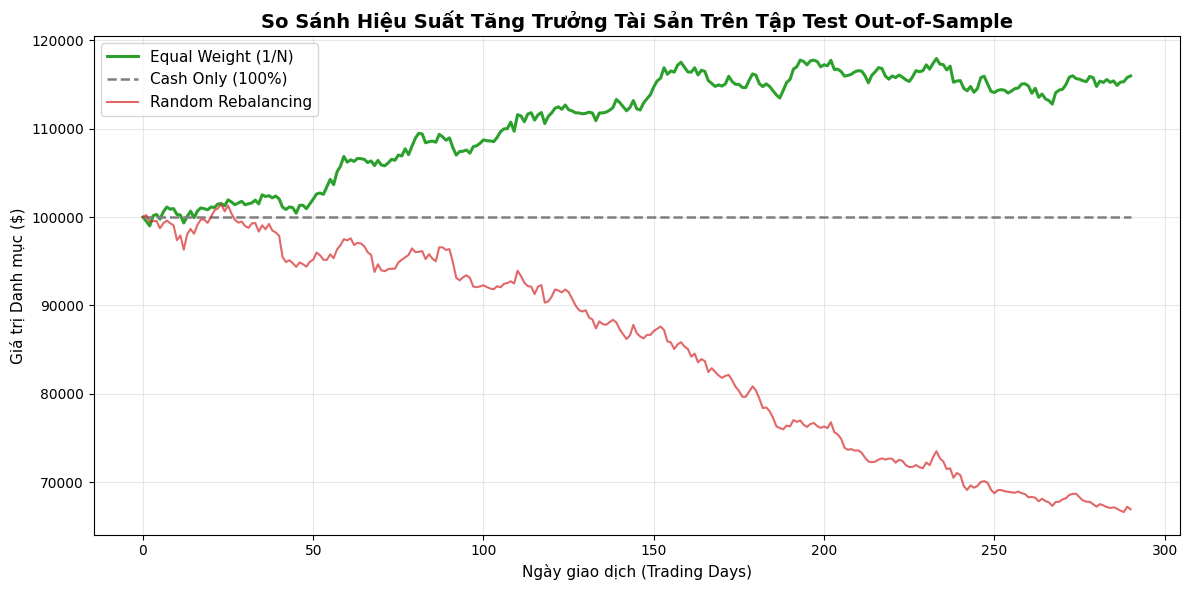

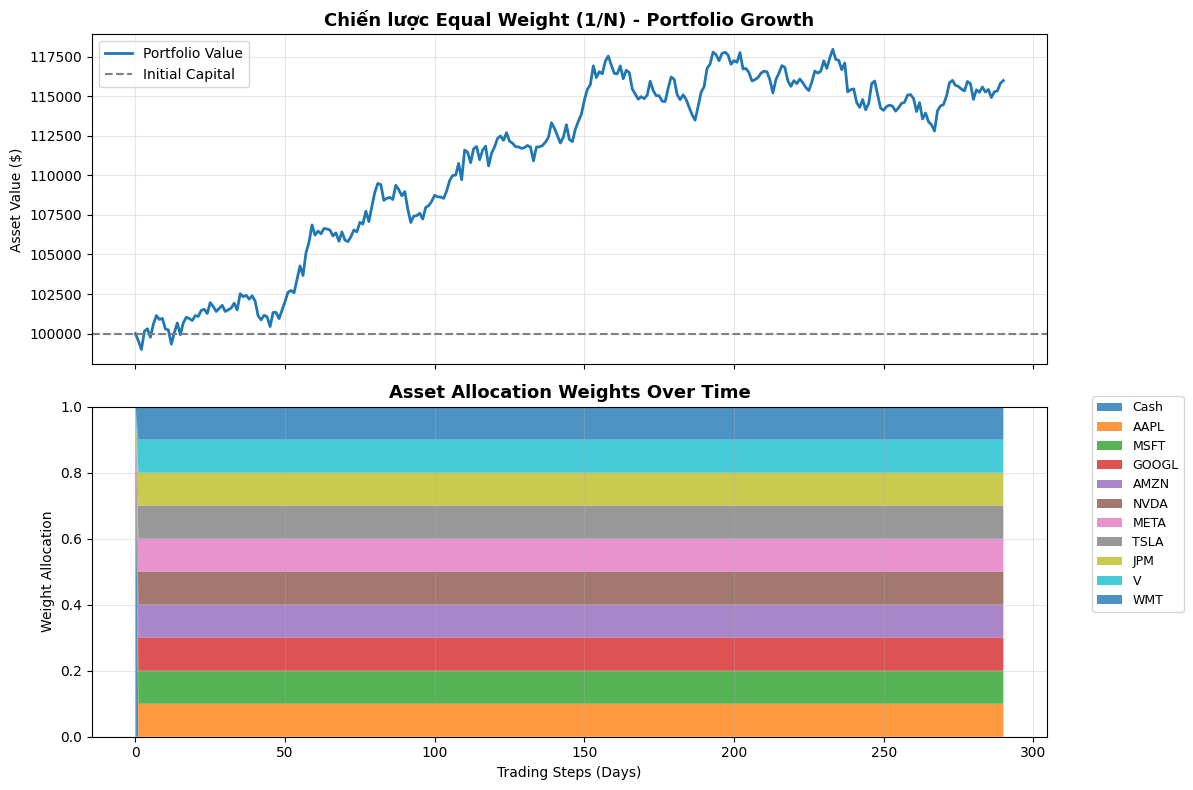

In [7]:
plt.figure(figsize=(12, 6))
plt.plot(history_ew, label='Equal Weight (1/N)', color='#2ca02c', lw=2.2)
plt.plot(history_cash, label='Cash Only (100%)', color='#7f7f7f', linestyle='--', lw=1.8)
plt.plot(history_rnd, label='Random Rebalancing', color='#d62728', alpha=0.7, lw=1.5)
plt.title('So Sánh Hiệu Suất Tăng Trưởng Tài Sản Trên Tập Test Out-of-Sample', fontsize=14, fontweight='bold')
plt.xlabel('Ngày giao dịch (Trading Days)', fontsize=11)
plt.ylabel('Giá trị Danh mục ($)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Vẽ phân bổ tỷ trọng chi tiết của chiến lược Equal Weight
test_env.reset()
for _ in range(test_env.T - 1):
    test_env.step(equal_weight_policy(None, test_env))
test_env.plot_results('Chiến lược Equal Weight (1/N)')


---
## 7. Tích hợp Với Stable-Baselines3 (PPO / SAC / A2C)

### Vấn đề tương thích kiến trúc:
- `FinRLPortfolioOptimizationEnv` xuất ra không gian quan sát dạng Tensor 3D $(F, N, M)$ và yêu cầu action thuộc mặt phẳng Simplex $\sum w_i = 1, w_i \ge 0$.
- Mạng `MlpPolicy` chuẩn trong **Stable-Baselines3** yêu cầu không gian quan sát 1 chiều phẳng (Flattened 1D vector).
- Do đó, ta tạo một lớp **Gymnasium Wrapper: `SB3PortfolioEnvWrapper`**:
  1. Trải phẳng (Flatten) quan sát $(F \times N \times M)$ thành vector $1D$ kích thước $(F \times N \times M)$.
  2. Tự động chuyển đổi đầu ra Gaussian Policy của SB3 thành vector xác suất Simplex bằng Softmax.
  3. Cung cấp API chuẩn cho `DummyVecEnv`.


In [8]:
class SB3PortfolioEnvWrapper(gym.ObservationWrapper):
    """
    Wrapper biến đổi môi trường FinRLPortfolioOptimizationEnv tương thích 100% với Stable-Baselines3.
    - Làm phẳng observation space thành Box(F * N * M,)
    - Action space giữ nguyên Box(N + 1,)
    """
    def __init__(self, env: FinRLPortfolioOptimizationEnv):
        super().__init__(env)
        flat_dim = env.num_features * env.num_stocks * env.time_window
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=(flat_dim,), dtype=np.float32
        )
        
    def observation(self, observation: np.ndarray) -> np.ndarray:
        if isinstance(observation, dict):
            obs = observation['state']
        else:
            obs = observation
        return obs.flatten().astype(np.float32)

print('✅ Lớp SB3PortfolioEnvWrapper đã sẵn sàng tích hợp!')


✅ Lớp SB3PortfolioEnvWrapper đã sẵn sàng tích hợp!


In [9]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv

# Đóng gói môi trường bằng Wrapper và VecEnv
wrapped_train_env = DummyVecEnv([lambda: SB3PortfolioEnvWrapper(train_env)])
wrapped_test_env = DummyVecEnv([lambda: SB3PortfolioEnvWrapper(test_env)])

print('>>> Khởi tạo mô hình PPO (Proximal Policy Optimization)...')
model = PPO(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=3e-4,
    n_steps=128,
    batch_size=32,
    gamma=0.99,
    ent_coef=0.01,
    verbose=0,
    seed=SEED
)

print('>>> Bắt đầu huấn luyện PPO trên 2,000 timesteps...')
model.learn(total_timesteps=2000)
print('✅ Hoàn thành huấn luyện PPO!')

# Đánh giá PPO trên tập Test
def ppo_policy(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _states = model.predict(flat_obs, deterministic=True)
    return action

m_ppo = evaluate_strategy(test_env, 'PPO Agent (SB3)', ppo_policy)
print('\n📊 KẾT QUẢ ĐÁNH GIÁ PPO AGENT:')
for k, v in m_ppo.items():
    print(f'  + {k}: {v}')


>>> Khởi tạo mô hình PPO (Proximal Policy Optimization)...
>>> Bắt đầu huấn luyện PPO trên 2,000 timesteps...
✅ Hoàn thành huấn luyện PPO!

📊 KẾT QUẢ ĐÁNH GIÁ PPO AGENT:
  + Final Value ($): 113477.48
  + Cumulative Return (%): 13.48
  + Annualized Return (%): 11.61
  + Annualized Volatility (%): 6.65
  + Sharpe Ratio: 1.685
  + Max Drawdown (%): -3.77
  + Strategy: PPO Agent (SB3)


## Khởi tạo thử nghiệm toàn bộ mô hình áp dụng được cho bài toán

Làm rõ và tái hiện lại tổng bộ thiết kế kiến trúc các mô hình thuật toán chính của mỗi mô hình

### Mô hình A2C

In [10]:
# ====================================================================
# 1. MÔ HÌNH A2C (Advantage Actor-Critic)
# ====================================================================
from stable_baselines3 import A2C

print('='*70)
print('>>> [1/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN A2C (Advantage Actor-Critic)')
print('='*70)

# 1. Khởi tạo mô hình A2C theo tham số chuẩn FinRL (A2C_PARAMS: n_steps=5, ent_coef=0.01, lr=0.0007)
a2c_model = A2C(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=0.0007,
    n_steps=5,                 # Cập nhật on-policy sau mỗi 5 bước (chu kỳ ngắn)
    gamma=0.99,
    ent_coef=0.01,             # Hệ số Entropy bonus chống kẹt cực tiểu cục bộ
    vf_coef=0.5,               # Trọng số Value loss
    max_grad_norm=0.5,         # Gradient clipping
    verbose=0,
    seed=SEED
)

# 2. Bóc tách kiến trúc mạng nơ-ron bên trong
print('\n📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA A2C:')
print(f'  • Policy Class:       {a2c_model.policy.__class__.__name__}')
print(f'  • Feature Extractor:  {a2c_model.policy.features_extractor.__class__.__name__} (Input: {a2c_model.observation_space.shape[0]} -> Output: {a2c_model.policy.features_dim})')
print(f'  • Shared/MLP Extractor: {a2c_model.policy.mlp_extractor}')
print(f'  • Actor Head (action_net): {a2c_model.policy.action_net} (Xuất vector kỳ vọng μ cho {train_env.action_dim} vị thế)')
print(f'  • Critic Head (value_net): {a2c_model.policy.value_net} (Xuất giá trị trạng thái vô hướng V(s))')
print(f'  • Action Distribution: {a2c_model.policy.action_dist.__class__.__name__} (DiagGaussian với tham số log_std độc lập)')

# 3. Huấn luyện mô hình
print('\n🚀 Bắt đầu huấn luyện A2C trên 2,000 timesteps...')
a2c_model.learn(total_timesteps=2000)
print('✅ Huấn luyện A2C hoàn tất!')

# 4. Đánh giá trên tập Test Out-of-Sample
def a2c_policy(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _ = a2c_model.predict(flat_obs, deterministic=True)
    return action

m_a2c = evaluate_strategy(test_env, 'A2C', a2c_policy)
history_a2c = test_env.asset_memory.copy()
sb3_all_results = [m_ew, m_cash, m_rnd, m_a2c]

print('\n📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ A2C:')
for k, v in m_a2c.items():
    if k != 'Strategy':
        print(f'  • {k}: {v}')

print('\n💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:')
print('  - A2C là thuật toán on-policy đồng bộ cập nhật theo batch ngắn (n_steps=5).')
print('  - Trong bài toán PM, do chu kỳ n_steps ngắn, A2C phản ứng nhanh với biến động giá ngắn hạn nhưng dễ bị nhiễu cao.')
print('  - Phân phối Gaussian của Actor được chiếu qua Softmax Simplex ở môi trường để bảo toàn tổng tỷ trọng = 1.')


>>> [1/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN A2C (Advantage Actor-Critic)

📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA A2C:
  • Policy Class:       ActorCriticPolicy
  • Feature Extractor:  FlattenExtractor (Input: 1200 -> Output: 1200)
  • Shared/MLP Extractor: MlpExtractor(
  (policy_net): Sequential(
    (0): Linear(in_features=1200, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
  )
  (value_net): Sequential(
    (0): Linear(in_features=1200, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
  )
)
  • Actor Head (action_net): Linear(in_features=64, out_features=11, bias=True) (Xuất vector kỳ vọng μ cho 11 vị thế)
  • Critic Head (value_net): Linear(in_features=64, out_features=1, bias=True) (Xuất giá trị trạng thái vô hướng V(s))
  • Action Distribution: DiagGaussianDistribution (DiagGaussian với tham số log_std độc lập)

🚀 Bắt đầu huấn luyện A2

### Mô hình PPO

In [11]:
# ====================================================================
# 2. MÔ HÌNH PPO (Proximal Policy Optimization)
# ====================================================================
from stable_baselines3 import PPO

print('='*70)
print('>>> [2/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN PPO (Proximal Policy Optimization)')
print('='*70)

# 1. Khởi tạo mô hình PPO theo chuẩn FinRL (PPO_PARAMS: n_steps=128/2048, batch_size=32/64, lr=0.00025)
ppo_model = PPO(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=0.00025,
    n_steps=128,               # Kích thước rollout buffer
    batch_size=32,             # Mini-batch size tối ưu hóa
    n_epochs=10,               # Số vòng lặp cập nhật trên mỗi rollout buffer
    gamma=0.99,
    gae_lambda=0.95,           # Hệ số Generalized Advantage Estimation
    clip_range=0.2,            # Ngưỡng xén tỷ số xác suất: 1 ± 0.2
    ent_coef=0.01,             # Entropy bonus thúc đẩy đa dạng hóa danh mục
    vf_coef=0.5,
    verbose=0,
    seed=SEED
)

# 2. Bóc tách kiến trúc mạng nơ-ron bên trong
print('\n📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA PPO:')
print(f'  • Policy Class:       {ppo_model.policy.__class__.__name__}')
print(f'  • Feature Extractor:  {ppo_model.policy.features_extractor.__class__.__name__}')
print(f'  • MLP Extractor (Tách nhánh Policy & Value riêng biệt):')
print(f'    - Policy Net (pi):  {ppo_model.policy.mlp_extractor.policy_net}')
print(f'    - Value Net (vf):   {ppo_model.policy.mlp_extractor.value_net}')
print(f'  • Action Head:        {ppo_model.policy.action_net} -> Output dimension: {train_env.action_dim}')
print(f'  • Value Head:         {ppo_model.policy.value_net} -> Output dimension: 1')
print(f'  • Cơ chế Clipped Surrogate: Ngăn chặn cập nhật chính sách quá lớn: r_t(θ) ∈ [0.8, 1.2]')

# 3. Huấn luyện mô hình
print('\n🚀 Bắt đầu huấn luyện PPO trên 2,000 timesteps...')
ppo_model.learn(total_timesteps=2000)
print('✅ Huấn luyện PPO hoàn tất!')

# 4. Đánh giá trên tập Test Out-of-Sample
def ppo_policy_fn(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _ = ppo_model.predict(flat_obs, deterministic=True)
    return action

m_ppo = evaluate_strategy(test_env, 'PPO', ppo_policy_fn)
history_ppo = test_env.asset_memory.copy()
sb3_all_results.append(m_ppo)

print('\n📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ PPO:')
for k, v in m_ppo.items():
    if k != 'Strategy':
        print(f'  • {k}: {v}')

print('\n💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:')
print('  - PPO ổn định hơn hẳn A2C nhờ cơ chế Surrogate Clipping, hạn chế việc thay đổi đột ngột tỷ trọng danh mục.')
print('  - Entropy bonus giúp tránh hiện tượng phân bổ 100% vào 1 mã duy nhất khi mới bắt đầu học.')


>>> [2/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN PPO (Proximal Policy Optimization)

📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA PPO:
  • Policy Class:       ActorCriticPolicy
  • Feature Extractor:  FlattenExtractor
  • MLP Extractor (Tách nhánh Policy & Value riêng biệt):
    - Policy Net (pi):  Sequential(
  (0): Linear(in_features=1200, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
)
    - Value Net (vf):   Sequential(
  (0): Linear(in_features=1200, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
)
  • Action Head:        Linear(in_features=64, out_features=11, bias=True) -> Output dimension: 11
  • Value Head:         Linear(in_features=64, out_features=1, bias=True) -> Output dimension: 1
  • Cơ chế Clipped Surrogate: Ngăn chặn cập nhật chính sách quá lớn: r_t(θ) ∈ [0.8, 1.2]

🚀 Bắt đầu huấn luyện PPO trên 2,000 timesteps...
✅ Huấn luyện PPO hoàn tất!

📊 

### Mô hình DDPG

In [12]:
# ====================================================================
# 3. MÔ HÌNH DDPG (Deep Deterministic Policy Gradient)
# ====================================================================
from stable_baselines3 import DDPG
from stable_baselines3.common.noise import OrnsteinUhlenbeckActionNoise

print('='*70)
print('>>> [3/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN DDPG (Deep Deterministic Policy Gradient)')
print('='*70)

# 1. Thiết lập Nhiễu hành động (Ornstein-Uhlenbeck Action Noise) chuẩn FinRL
n_actions = train_env.action_dim
ou_noise = OrnsteinUhlenbeckActionNoise(mean=np.zeros(n_actions), sigma=0.1 * np.ones(n_actions))

# 2. Khởi tạo mô hình DDPG (buffer_size an toàn 10,000 tránh tràn RAM)
ddpg_model = DDPG(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=0.001,
    buffer_size=10_000,        # Replay Buffer lưu trữ chuyển trạng thái (s, a, r, s')
    batch_size=64,
    tau=0.005,                 # Hệ số Polyak update mạng target
    gamma=0.99,
    action_noise=ou_noise,     # Nhiễu khám phá tự tương quan theo thời gian
    verbose=0,
    seed=SEED
)

# 3. Bóc tách kiến trúc mạng nơ-ron bên trong
print('\n📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA DDPG:')
print(f'  • Policy Class:          {ddpg_model.policy.__class__.__name__}')
print(f'  • Actor (Deterministic): {ddpg_model.policy.actor}')
print(f'    - Lớp cuối Actor:      Linear -> Tanh() (Ép hành động về [-1, 1], sau đó co giãn về [0, 1])')
print(f'  • Critic (Q-network):    {ddpg_model.policy.critic}')
print(f'    - Đầu vào Critic:      Ghép nối [State, Action] kích thước {a2c_model.observation_space.shape[0]} + {n_actions}')
print(f'  • Target Networks:       actor_target & critic_target cập nhật chậm qua Polyak (tau=0.005)')

# 4. Huấn luyện mô hình
print('\n🚀 Bắt đầu huấn luyện DDPG trên 2,000 timesteps...')
ddpg_model.learn(total_timesteps=2000)
print('✅ Huấn luyện DDPG hoàn tất!')

# 5. Đánh giá trên tập Test Out-of-Sample
def ddpg_policy_fn(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _ = ddpg_model.predict(flat_obs, deterministic=True)
    return action

m_ddpg = evaluate_strategy(test_env, 'DDPG', ddpg_policy_fn)
history_ddpg = test_env.asset_memory.copy()
sb3_all_results.append(m_ddpg)

print('\n📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ DDPG:')
for k, v in m_ddpg.items():
    if k != 'Strategy':
        print(f'  • {k}: {v}')

print('\n💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:')
print('  - DDPG xuất ra hành động tất định, loại bỏ hoàn toàn độ ngẫu nhiên khi đưa ra quyết định.')
print('  - Tuy nhiên, DDPG chỉ có 1 Critic duy nhất nên rất dễ bị hiện tượng Overestimation Bias (ước lượng lợi nhuận quá mức).')


>>> [3/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN DDPG (Deep Deterministic Policy Gradient)

📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA DDPG:
  • Policy Class:          TD3Policy
  • Actor (Deterministic): Actor(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mu): Sequential(
    (0): Linear(in_features=1200, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=300, bias=True)
    (3): ReLU()
    (4): Linear(in_features=300, out_features=11, bias=True)
    (5): Tanh()
  )
)
    - Lớp cuối Actor:      Linear -> Tanh() (Ép hành động về [-1, 1], sau đó co giãn về [0, 1])
  • Critic (Q-network):    ContinuousCritic(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (qf0): Sequential(
    (0): Linear(in_features=1211, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=300, bias=True)
    (3): ReLU()
    (4): Linear(in_features=

### Mô hình TD3

In [13]:
# ====================================================================
# 4. MÔ HÌNH TD3 (Twin Delayed DDPG)
# ====================================================================
from stable_baselines3 import TD3
from stable_baselines3.common.noise import NormalActionNoise

print('='*70)
print('>>> [4/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN TD3 (Twin Delayed DDPG)')
print('='*70)

# 1. Nhiễu hành động Gaussian cho TD3
gauss_noise = NormalActionNoise(mean=np.zeros(n_actions), sigma=0.1 * np.ones(n_actions))

# 2. Khởi tạo mô hình TD3
td3_model = TD3(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=0.001,
    buffer_size=10_000,        # Safe buffer size
    batch_size=64,
    tau=0.005,
    gamma=0.99,
    policy_delay=2,            # Cập nhật Actor 1 lần sau mỗi 2 lần cập nhật Critic
    target_policy_noise=0.2,   # Nhiễu làm mịn mục tiêu (Target Policy Smoothing)
    target_noise_clip=0.5,
    action_noise=gauss_noise,
    verbose=0,
    seed=SEED
)

# 3. Bóc tách kiến trúc mạng nơ-ron bên trong
print('\n📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA TD3:')
print(f'  • Policy Class:       {td3_model.policy.__class__.__name__}')
print(f'  • Actor Network:      {td3_model.policy.actor}')
print(f'  • Twin Critics (2 mạng Q độc lập Q1 và Q2):') 
print(f'    - Critic 1 (qf0):   {td3_model.policy.critic.q_networks[0]}')
print(f'    - Critic 2 (qf1):   {td3_model.policy.critic.q_networks[1]}')
print('  • Cơ chế Clipped Double Q: Lấy giá trị nhỏ nhất min(Q1, Q2) khi tính Bellman target -> Trị tận gốc overestimation!')

# 4. Huấn luyện mô hình
print('\n🚀 Bắt đầu huấn luyện TD3 trên 2,000 timesteps...')
td3_model.learn(total_timesteps=2000)
print('✅ Huấn luyện TD3 hoàn tất!')

# 5. Đánh giá trên tập Test Out-of-Sample
def td3_policy_fn(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _ = td3_model.predict(flat_obs, deterministic=True)
    return action

m_td3 = evaluate_strategy(test_env, 'TD3', td3_policy_fn)
history_td3 = test_env.asset_memory.copy()
sb3_all_results.append(m_td3)

print('\n📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ TD3:')
for k, v in m_td3.items():
    if k != 'Strategy':
        print(f'  • {k}: {v}')

print('\n💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:')
print('  - TD3 cải thiện vượt trội so với DDPG trong môi trường tài chính vì loại bỏ sự ảo tưởng về lợi nhuận qua Twin Critics.')
print('  - Target Policy Smoothing giúp danh mục chống lại các điểm cực đoan của hàm Q đối với các mã cổ phiếu rủi ro.')


>>> [4/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN TD3 (Twin Delayed DDPG)

📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA TD3:
  • Policy Class:       TD3Policy
  • Actor Network:      Actor(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mu): Sequential(
    (0): Linear(in_features=1200, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=300, bias=True)
    (3): ReLU()
    (4): Linear(in_features=300, out_features=11, bias=True)
    (5): Tanh()
  )
)
  • Twin Critics (2 mạng Q độc lập Q1 và Q2):
    - Critic 1 (qf0):   Sequential(
  (0): Linear(in_features=1211, out_features=400, bias=True)
  (1): ReLU()
  (2): Linear(in_features=400, out_features=300, bias=True)
  (3): ReLU()
  (4): Linear(in_features=300, out_features=1, bias=True)
)
    - Critic 2 (qf1):   Sequential(
  (0): Linear(in_features=1211, out_features=400, bias=True)
  (1): ReLU()
  (2): Linear(in_features=400, out_features=300, bias=True)
  (3

### Mô hình SAC

In [14]:
# ====================================================================
# 5. MÔ HÌNH SAC (Soft Actor-Critic)
# ====================================================================
from stable_baselines3 import SAC

print('='*70)
print('>>> [5/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN SAC (Soft Actor-Critic)')
print('='*70)

# 1. Khởi tạo mô hình SAC với Auto Entropy Tuning
sac_model = SAC(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=0.0003,
    buffer_size=10_000,
    batch_size=64,
    tau=0.005,
    gamma=0.99,
    ent_coef='auto',           # Tự động tối ưu hóa nhiệt độ Entropy alpha theo target entropy
    learning_starts=100,
    verbose=0,
    seed=SEED
)

# 2. Bóc tách kiến trúc mạng nơ-ron bên trong
print('\n📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA SAC:')
print(f'  • Policy Class:       {sac_model.policy.__class__.__name__}')
print(f'  • Stochastic Actor:   {sac_model.policy.actor}')
print(f'    - Nhánh mu:         {sac_model.policy.actor.mu}')
print(f'    - Nhánh log_std:    {sac_model.policy.actor.log_std}')
print(f'  • Action Distribution: SquashedDiagGaussianDistribution (Áp dụng Tanh(u) + Jacobian log-prob correction)')
print(f'  • Twin Soft Critics:  2 mạng Critic Q1 và Q2 có tính thành phần -alpha * log pi(a|s)')
print(f'  • Tham số Entropy alpha học được: log_ent_coef = {sac_model.log_ent_coef.item():.4f}')

# 3. Huấn luyện mô hình
print('\n🚀 Bắt đầu huấn luyện SAC trên 2,000 timesteps...')
sac_model.learn(total_timesteps=2000)
print('✅ Huấn luyện SAC hoàn tất!')

# 4. Đánh giá trên tập Test Out-of-Sample
def sac_policy_fn(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _ = sac_model.predict(flat_obs, deterministic=True)
    return action

m_sac = evaluate_strategy(test_env, 'SAC', sac_policy_fn)
history_sac = test_env.asset_memory.copy()
sb3_all_results.append(m_sac)

print('\n📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ SAC:')
for k, v in m_sac.items():
    if k != 'Strategy':
        print(f'  • {k}: {v}')

print('\n💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:')
print('  - Nguyên lý Maximum Entropy của SAC là công cụ tự nhiên tuyệt vời cho đa dạng hóa danh mục (Diversification).')
print('  - Thay vì chỉ tìm một danh mục tối ưu đơn lẻ, SAC tìm một chính sách phân bổ có entropy cao, giảm thiểu rủi ro tập trung.')


>>> [5/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN SAC (Soft Actor-Critic)

📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA SAC:
  • Policy Class:       SACPolicy
  • Stochastic Actor:   Actor(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (latent_pi): Sequential(
    (0): Linear(in_features=1200, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
  )
  (mu): Linear(in_features=256, out_features=11, bias=True)
  (log_std): Linear(in_features=256, out_features=11, bias=True)
)
    - Nhánh mu:         Linear(in_features=256, out_features=11, bias=True)
    - Nhánh log_std:    Linear(in_features=256, out_features=11, bias=True)
  • Action Distribution: SquashedDiagGaussianDistribution (Áp dụng Tanh(u) + Jacobian log-prob correction)
  • Twin Soft Critics:  2 mạng Critic Q1 và Q2 có tính thành phần -alpha * log pi(a|s)
  • Tham số Entropy alpha học được: log_ent_coef = 0.0000

🚀 Bắt 

### Mô hình TQC

In [18]:
# ====================================================================
# 6. MÔ HÌNH TQC (Truncated Quantile Critics)
# ====================================================================
from sb3_contrib import TQC

print('='*70)
print('>>> [6/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN TQC (Truncated Quantile Critics)')
print('='*70)

# 1. Khởi tạo mô hình TQC (sb3-contrib)
tqc_model = TQC(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=0.0003,
    buffer_size=10_000,
    batch_size=64,
    gamma=0.99,
    top_quantiles_to_drop_per_net=2, # Cắt bỏ 2 quantiles cao nhất của mỗi mạng Critic
    verbose=0,
    seed=SEED
)

# 2. Bóc tách kiến trúc mạng nơ-ron bên trong
print('\n📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA TQC:')
print(f'  • Policy Class:          {tqc_model.policy.__class__.__name__}')
print(f'  • Quantile Critic:       {tqc_model.policy.critic.__class__.__name__}')
# print(f'    - Số lượng Critic Nets: {tqc_model.n_critics}')
# print(f'    - Số Quantiles / Net:   {tqc_model.quantiles_total // tqc_model.n_critics}')
# print(f'    - Tổng số Quantiles:    {tqc_model.quantiles_total}')
# print(f'    - Số Quantiles bị cắt:  {tqc_model.top_quantiles_to_drop_per_net * tqc_model.n_critics} (loại trừ các giá trị kỳ vọng ảo)')
print('  • Cơ chế Phân vị: Ước lượng toàn bộ phân phối xác suất của lợi nhuận thay vì chỉ ước lượng giá trị trung bình!')

# 3. Huấn luyện mô hình
print('\n🚀 Bắt đầu huấn luyện TQC trên 2,000 timesteps...')
tqc_model.learn(total_timesteps=2000)
print('✅ Huấn luyện TQC hoàn tất!')

# 4. Đánh giá trên tập Test Out-of-Sample
def tqc_policy_fn(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _ = tqc_model.predict(flat_obs, deterministic=True)
    return action

m_tqc = evaluate_strategy(test_env, 'TQC', tqc_policy_fn)
history_tqc = test_env.asset_memory.copy()
sb3_all_results.append(m_tqc)

print('\n📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ TQC:')
for k, v in m_tqc.items():
    if k != 'Strategy':
        print(f'  • {k}: {v}')

print('\n💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:')
print('  - TQC là thuật toán đoạt giải tiên tiến nhất cho thị trường tài chính biến động (đặc biệt Crypto / Volatile stocks).')
print('  - Việc cắt bỏ quantiles cao giúp loại trừ thiên kiến lạc quan tếu (Over-optimism) trước các đợt tăng giá ảo ngắn hạn.')


>>> [6/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN TQC (Truncated Quantile Critics)

📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA TQC:
  • Policy Class:          TQCPolicy
  • Quantile Critic:       Critic
  • Cơ chế Phân vị: Ước lượng toàn bộ phân phối xác suất của lợi nhuận thay vì chỉ ước lượng giá trị trung bình!

🚀 Bắt đầu huấn luyện TQC trên 2,000 timesteps...
✅ Huấn luyện TQC hoàn tất!

📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ TQC:
  • Final Value ($): 114472.58
  • Cumulative Return (%): 14.47
  • Annualized Return (%): 12.46
  • Annualized Volatility (%): 7.13
  • Sharpe Ratio: 1.684
  • Max Drawdown (%): -3.94

💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:
  - TQC là thuật toán đoạt giải tiên tiến nhất cho thị trường tài chính biến động (đặc biệt Crypto / Volatile stocks).
  - Việc cắt bỏ quantiles cao giúp loại trừ thiên kiến lạc quan tếu (Over-optimism) trước các đợt tăng giá ảo ngắn hạn.


### Mô hình CrossQ

In [19]:
# ====================================================================
# 7. MÔ HÌNH CrossQ (Batch Normalization in Deep RL)
# ====================================================================
from sb3_contrib import CrossQ

print('='*70)
print('>>> [7/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN CrossQ (ICLR 2024)')
print('='*70)

# 1. Khởi tạo mô hình CrossQ (sb3-contrib)
crossq_model = CrossQ(
    policy='MlpPolicy',
    env=wrapped_train_env,
    learning_rate=0.001,
    buffer_size=10_000,
    batch_size=64,
    gamma=0.99,
    verbose=0,
    seed=SEED
)

# 2. Bóc tách kiến trúc mạng nơ-ron bên trong
print('\n📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA CrossQ:')
print(f'  • Policy Class:       {crossq_model.policy.__class__.__name__}')
print(f'  • Cơ chế Đột phá:     HOÀN TOÀN KHÔNG SỬ DỤNG TARGET NETWORKS (No Target Delay)!') 
print(f'  • Batch Normalization: Áp dụng trực tiếp vào Critic: {crossq_model.policy.critic}')
print('  • Cross-Batching: Gộp chung (s_t, a_t) và (s_{t+1}, a_{t+1}) trong cùng một lượt forward để chuẩn hóa thống kê.')

# 3. Huấn luyện mô hình
print('\n🚀 Bắt đầu huấn luyện CrossQ trên 2,000 timesteps...')
crossq_model.learn(total_timesteps=2000)
print('✅ Huấn luyện CrossQ hoàn tất!')

# 4. Đánh giá trên tập Test Out-of-Sample
def crossq_policy_fn(obs, env):
    flat_obs = obs.flatten().astype(np.float32)
    action, _ = crossq_model.predict(flat_obs, deterministic=True)
    return action

m_crossq = evaluate_strategy(test_env, 'CrossQ', crossq_policy_fn)
history_crossq = test_env.asset_memory.copy()
sb3_all_results.append(m_crossq)

print('\n📊 KẾT QUẢ ĐÁNH GIÁ THỰC TẾ CrossQ:')
for k, v in m_crossq.items():
    if k != 'Strategy':
        print(f'  • {k}: {v}')

print('\n💡 NHẬN XÉT ĐẶC THÙ CHO BÀI TOÁN PORTFOLIO MANAGEMENT:')
print('  - CrossQ giải quyết bài toán trễ thông tin trong DRL tài chính: Học trực tiếp không cần chờ mạng Target bắt kịp.')
print('  - Tầng Batch Normalization giữ cho gradient ổn định bất chấp dữ liệu giá tài chính có biến động thang đo lớn.')


>>> [7/7] PHÂN TÍCH KIẾN TRÚC MẠNG & THUẬT TOÁN CrossQ (ICLR 2024)

📐 BÓC TÁCH KIẾN TRÚC MẠNG NƠ-RON CỦA CrossQ:
  • Policy Class:       CrossQPolicy
  • Cơ chế Đột phá:     HOÀN TOÀN KHÔNG SỬ DỤNG TARGET NETWORKS (No Target Delay)!
  • Batch Normalization: Áp dụng trực tiếp vào Critic: CrossQCritic(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (qf0): Sequential(
    (0): BatchRenorm1d(num_features=1211, momentum=0.01, warmup_steps=100000, affine=True)
    (1): Linear(in_features=1211, out_features=1024, bias=True)
    (2): ReLU()
    (3): BatchRenorm1d(num_features=1024, momentum=0.01, warmup_steps=100000, affine=True)
    (4): Linear(in_features=1024, out_features=1024, bias=True)
    (5): ReLU()
    (6): BatchRenorm1d(num_features=1024, momentum=0.01, warmup_steps=100000, affine=True)
    (7): Linear(in_features=1024, out_features=1, bias=True)
  )
  (qf1): Sequential(
    (0): BatchRenorm1d(num_features=1211, momentum=0.01, warmup_

---
## 📊 BẢNG SO SÁNH TỔNG HỢP TOÀN BỘ 7 THUẬT TOÁN BASELINE & BENCHMARKS

Dưới đây là bảng đối chiếu hiệu suất chi tiết giữa tất cả các thuật toán Reinforcement Learning và các danh mục Benchmark chuẩn (Equal-Weight $1/N$, 100% Cash, Random):


🏆 BẢNG XẾP HẠNG HIỆU SUẤT CÁC THUẬT TOÁN TRÊN TẬP TEST OUT-OF-SAMPLE:
                    Final Value ($)  Cumulative Return (%)  Annualized Return (%)  Annualized Volatility (%)  Sharpe Ratio  Max Drawdown (%)
Strategy                                                                                                                                    
Equal Weight (1/N)        115984.43                  15.98                  13.75                       7.87         1.677             -4.37
Cash Only (100%)          100000.00                   0.00                   0.00                       0.00         0.000              0.00
Random Rebalancing         66915.86                 -33.08                 -29.47                      10.26        -3.349            -34.35
A2C                       113237.30                  13.24                  11.41                       8.44         1.323             -5.21
PPO                       113387.06                  13.39                  11.54   

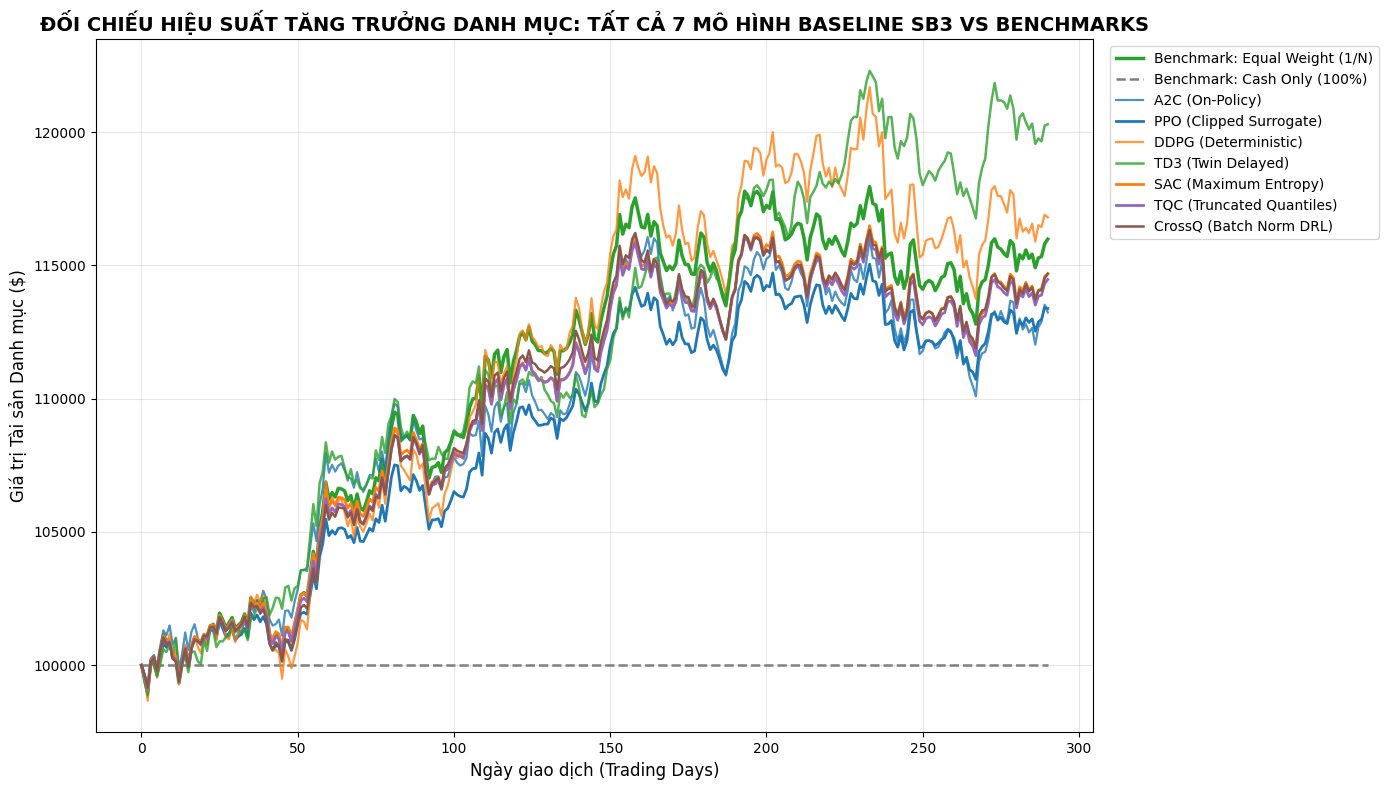

In [20]:
# 1. Tạo DataFrame tổng hợp toàn bộ kết quả
df_final_comparison = pd.DataFrame(sb3_all_results)
df_final_comparison.set_index('Strategy', inplace=True)
print('='*85)
print('🏆 BẢNG XẾP HẠNG HIỆU SUẤT CÁC THUẬT TOÁN TRÊN TẬP TEST OUT-OF-SAMPLE:')
print('='*85)
print(df_final_comparison.to_string())

# 2. Vẽ biểu đồ tăng trưởng vốn (Equity Curves) đối chiếu tất cả thuật toán
plt.figure(figsize=(14, 8))
plt.plot(history_ew, label='Benchmark: Equal Weight (1/N)', color='#2ca02c', lw=2.5, linestyle='-')
plt.plot(history_cash, label='Benchmark: Cash Only (100%)', color='#7f7f7f', lw=1.8, linestyle='--')
plt.plot(history_a2c, label='A2C (On-Policy)', alpha=0.8, lw=1.6)
plt.plot(history_ppo, label='PPO (Clipped Surrogate)', color='#1f77b4', lw=2.0)
plt.plot(history_ddpg, label='DDPG (Deterministic)', alpha=0.8, lw=1.6)
plt.plot(history_td3, label='TD3 (Twin Delayed)', alpha=0.8, lw=1.8)
plt.plot(history_sac, label='SAC (Maximum Entropy)', color='#ff7f0e', lw=2.0)
plt.plot(history_tqc, label='TQC (Truncated Quantiles)', color='#9467bd', lw=2.0)
plt.plot(history_crossq, label='CrossQ (Batch Norm DRL)', color='#8c564b', lw=1.8)

plt.title('ĐỐI CHIẾU HIỆU SUẤT TĂNG TRƯỞNG DANH MỤC: TẤT CẢ 7 MÔ HÌNH BASELINE SB3 VS BENCHMARKS', fontsize=14, fontweight='bold')
plt.xlabel('Ngày giao dịch (Trading Days)', fontsize=12)
plt.ylabel('Giá trị Tài sản Danh mục ($)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1.0), fontsize=10)
plt.tight_layout()
plt.show()
